# Coordenadas de las ciudades

Este notebook arma `coordenadas_ciudades.csv`, la tabla con la latitud, la longitud, la altura y la distancia al mar
de la estación meteorológica de cada ciudad que usa `TP-clasificacion-AA1.ipynb`, y la controla. El dataset trae el
nombre de cada ciudad pero no de qué estación salen sus datos, así que la correspondencia entre ciudad y
estación la construimos acá, a partir del listado oficial de estaciones del Bureau of Meteorology (el
servicio meteorológico de Australia), y la contrastamos con el propio dataset.

In [28]:
# Bibliotecas y rutas: el listado se guarda en esta carpeta, y el dataset y la tabla están en la carpeta del TP
import json
import re
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

URL_LISTADO = "ftp://ftp.bom.gov.au/anon2/home/ncc/metadata/sitelists/stations.txt"
LISTADO = Path("estaciones_bom.txt")
URL_COSTA = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/v5.1.2/geojson/ne_10m_coastline.geojson"
COSTA = Path("costa_ne_10m.geojson")
DATASET = Path("../weatherAUS_2026C2.csv")
TABLA = Path("../coordenadas_ciudades.csv")
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 120)

## El listado de estaciones

In [29]:
# Bajamos el listado del servidor FTP del Bureau of Meteorology la primera vez, y después usamos la copia guardada
if not LISTADO.exists():
    urllib.request.urlretrieve(URL_LISTADO, LISTADO)
lineas = LISTADO.read_text(encoding="latin-1").splitlines()
print("\n".join(lineas[:4] + ["..."] + lineas[-2:]))

Bureau of Meteorology product IDCJMC0014.                                       Produced: 10 Jun 2015

   Site  Dist  Site name                                 Start     End      Lat       Lon Source         STA Height (m)   Bar_ht    WMO
------- ----- ---------------------------------------- ------- ------- -------- --------- -------------- --- ---------- -------- ------
...
Please note Copyright, Disclaimer and Privacy Notice, accessible at <http://www.bom.gov.au/other/copyright.shtml>



El encabezado identifica el archivo: el producto `IDCJMC0014` del Bureau of Meteorology, generado el 10 de
junio de 2015. Es de ancho fijo, y la línea de guiones marca dónde empieza y termina cada columna. Las dos
últimas líneas son el aviso de copyright.

In [30]:
# Leemos el ancho fijo ubicando cada columna con la línea de guiones, y nos quedamos con las filas que son estaciones
columnas = [(m.start(), m.end()) for m in re.finditer(r"-+", lineas[3])]
nombres = ["numero", "distrito", "nombre", "inicio", "cierre", "latitud", "longitud", "fuente", "estado", "altura", "altura_barometro", "omm"]
crudo = pd.read_fwf(LISTADO, colspecs=columnas, names=nombres, skiprows=4, encoding="latin-1", dtype=str)
es_estacion = crudo["numero"].str.fullmatch(r"\d{6}", na=False)
estaciones = crudo[es_estacion].set_index("numero")
print(f"Filas leídas: {len(crudo)}  |  Estaciones: {len(estaciones)}  |  Filas que no son estaciones: {crudo.loc[~es_estacion, 'numero'].tolist()}")
estaciones.head()

Filas leídas: 20108  |  Estaciones: 20105  |  Filas que no son estaciones: ['20105 s', '(c) Cop', 'Please']


,distrito,nombre,inicio,cierre,latitud,longitud,fuente,estado,altura,altura_barometro,omm
numero,,,,,,,,,,,
001000,01,KARUNJIE,1940,1983,-16.2919,127.1956,.....,WA,320.0,..,..
001001,01,OOMBULGURRI,1914,2012,-15.1806,127.8456,GPS,WA,2.0,..,..
001002,01,BEVERLEY SP,1959,1967,-16.5825,125.4828,.....,WA,..,..,..
001003,01,PAGO MISSION,1908,1940,-14.1331,126.7158,.....,WA,5.0,24.4,..
001004,01,KUNMUNYA,1915,1948,-15.4167,124.7167,.....,WA,47.0,..,..


In [31]:
# Años y coordenadas a números, y si la estación tiene barómetro y número OMM
estaciones = estaciones.assign(inicio=estaciones["inicio"].astype(int), cierre=pd.to_numeric(estaciones["cierre"], errors="coerce"),
                               latitud=estaciones["latitud"].astype(float), longitud=estaciones["longitud"].astype(float),
                               barometro=estaciones["altura_barometro"].ne(".."), con_omm=estaciones["omm"].ne(".."))
print(f"Sin año de cierre: {estaciones['cierre'].isna().sum()}  |  Con barómetro: {estaciones['barometro'].sum()}  |  Con número OMM: {estaciones['con_omm'].sum()}")

Sin año de cierre: 7578  |  Con barómetro: 975  |  Con número OMM: 937


In [32]:
# De dónde sale la coordenada de cada estación
estaciones["fuente"].value_counts().to_frame("estaciones")

,estaciones
fuente,
.....,11567
GPS,8065
MAP 1:25 000,118
MAP 1:250 000,112
Unknown,72
SURVEY,45
MAP 1:100 000,45
MAP 1:50 000,33
DEM 3 Sec SRTM,18


En el listado, `..` indica que el dato no existe. Lo leemos así: una estación sin año de cierre sigue
abierta, una sin altura de barómetro (`Bar_ht`) no tiene barómetro, y una sin número OMM no lo tiene. Que
la falta de altura de barómetro signifique que no hay barómetro es una interpretación nuestra, y la
contrastamos con el dataset en las dos secciones siguientes.

De las 20.105 estaciones, 7.578 no tienen año de cierre, 975 tienen barómetro y 937 tienen número OMM: el
listado incluye estaciones históricas y puestos que miden pocas cosas. La coordenada está relevada con GPS
en 8.065 estaciones; en 11.567 la fuente no está registrada (`.....`), y el resto sale de mapas,
relevamientos (`SURVEY`) o modelos de elevación (`DEM`).

## Lo que el dataset dice de cada ciudad

In [33]:
# Para cada ciudad: el período que cubre y en qué porcentaje de sus días tiene algún dato de presión
datos = pd.read_csv(DATASET, usecols=["Date", "Location", "Rainfall", "Pressure9am", "Pressure3pm"], parse_dates=["Date"])
ciudades = datos.groupby("Location").agg(desde=("Date", "min"), hasta=("Date", "max"))
ciudades["% días con presión"] = datos[["Pressure9am", "Pressure3pm"]].notna().any(axis=1).groupby(datos["Location"]).mean().mul(100).round(1)
ciudades["presion"] = ciudades["% días con presión"] > 0
ciudades.sort_values("% días con presión")

,desde,hasta,% días con presión,presion
Location,,,,
Newcastle,2008-12-01,2017-06-24,0.0,False
Penrith,2008-12-01,2017-06-24,0.0,False
MountGinini,2008-12-01,2017-06-24,0.0,False
SalmonGums,2009-01-01,2017-06-24,0.0,False
Launceston,2008-12-01,2017-06-24,62.1,True
Melbourne,2008-07-01,2017-06-24,85.0,True
CoffsHarbour,2009-01-01,2017-06-24,89.9,True
Canberra,2007-11-01,2017-06-24,93.8,True
BadgerysCreek,2009-01-01,2017-06-24,94.9,True


Cuatro ciudades no tienen ni un dato de presión en todo el período: Newcastle, Penrith, MountGinini y
SalmonGums. Las demás tienen presión en la mayoría de sus días; las que menos, Launceston (62,1%) y
Melbourne (85,0%).

Una estación sin barómetro no puede registrar presión, así que una ciudad con presión tiene que salir de
una estación con barómetro. Al revés la regla no es tan estricta, porque una estación con barómetro podría
no informar la presión, pero que una ciudad no tenga ni un dato en más de ocho años se explica mucho mejor
con una estación sin barómetro. Es el único dato del listado que se puede contrastar con lo que mide cada
ciudad, y lo usamos como requisito.

## Candidatas

Una estación es candidata para una ciudad si cumple todos estos requisitos:

- Su nombre contiene el de la ciudad. El nombre del dataset se separa en palabras (`GoldCoast` pasa a
  `GOLD COAST`) y se busca como comienzo de palabra, para que `ULURU` no encuentre `MULURULU`. Así, `Nhil`
  como está escrito en el dataset encuentra `NHILL`.
- Estuvo abierta en algún momento del período que cubre la ciudad en el dataset.
- Tiene número OMM (de la Organización Meteorológica Mundial). Lo pedimos para quedarnos con estaciones
  que se informan a nivel internacional y no con puestos que sólo miden alguna variable, pero es una
  suposición nuestra: el listado no dice qué mide cada estación, salvo la presión.
- Su nombre no dice que sea un radar (`RADAR`), un perfilador de viento (`PROFILER`) o un anemómetro
  (`ANEMOMETER`), que no miden las variables del dataset.
- Tiene barómetro si la ciudad tiene datos de presión, y no lo tiene si la ciudad nunca los tuvo.

Si ninguna estación con el nombre de la ciudad cumple todo, tomamos la estación que cumpla todo lo demás
más cercana a alguna de las que tienen ese nombre, a no más de 30 km.

In [34]:
def km(lat1, lon1, lat2, lon2):
    """Distancia en km sobre la superficie de la Tierra entre puntos dados en grados (fórmula del haversine)."""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    h = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(h))

In [35]:
def termino(ciudad):
    """El nombre de la ciudad como se busca en el listado: separado en palabras y en mayúsculas."""
    return re.sub(r"(?<=[a-z])(?=[A-Z])", " ", ciudad).upper()


def requisitos(e, ciudad):
    """Qué requisitos, además del nombre, cumple cada estación de e para la ciudad."""
    c = ciudades.loc[ciudad]
    return pd.DataFrame({"abierta en el período": (e["inicio"] <= c["hasta"].year) & (e["cierre"].isna() | (e["cierre"] >= c["desde"].year)),
                         "con número OMM": e["con_omm"],
                         "no es radar ni similar": ~e["nombre"].str.contains("RADAR|PROFILER|ANEMOMETER"),
                         "barómetro según la presión": e["barometro"] == c["presion"]})

In [36]:
# Para cada ciudad, cuántas estaciones con su nombre siguen en pie después de cada requisito, aplicados en orden
con_nombre = {ciudad: estaciones[estaciones["nombre"].str.contains(rf"\b{termino(ciudad)}")] for ciudad in ciudades.index}
pasos = pd.DataFrame({ciudad: requisitos(e, ciudad).astype(int).cumprod(axis=1).sum() for ciudad, e in con_nombre.items()}).T
pasos.insert(0, "con el nombre", [len(e) for e in con_nombre.values()])
pasos

,con el nombre,abierta en el período,con número OMM,no es radar ni similar,barómetro según la presión
Adelaide,56,33,6,2,2
Albany,5,3,3,3,2
Albury,8,4,1,1,1
AliceSprings,9,5,1,1,1
BadgerysCreek,3,1,1,1,1
Ballarat,6,2,1,1,1
Bendigo,4,1,1,1,1
Brisbane,17,12,3,3,2
Cairns,7,6,2,2,1
Canberra,11,5,1,1,1


In [37]:
# Las estaciones con el nombre de la ciudad que cumplen todo salvo el requisito del barómetro
filas = []
for ciudad, e in con_nombre.items():
    r = requisitos(e, ciudad)
    descartadas = e[r.drop(columns="barómetro según la presión").all(axis=1) & ~r["barómetro según la presión"]]
    filas += [{"ciudad": ciudad, "% días con presión": ciudades.loc[ciudad, "% días con presión"], "estación": f"{n} {fila['nombre']}",
               "tiene barómetro": fila["barometro"]} for n, fila in descartadas.iterrows()]
pd.DataFrame(filas)

,ciudad,% días con presión,estación,tiene barómetro
0,Albany,99.4,009500 ALBANY,False
1,Brisbane,100.0,040966 BRISBANE (MT STAPYLTON),False
2,Cairns,100.0,031222 CAIRNS RACECOURSE,False
3,Hobart,100.0,094256 HOBART (MT KOONYA),False
4,Katherine,100.0,014305 KATHERINE COUNTRY CLUB,False
5,Launceston,62.1,091237 LAUNCESTON (TI TREE BEND),False
6,Richmond,99.6,058221 LISMORE (RICHMOND HILL),False
7,Richmond,99.6,094177 RICHMOND (STRATHAYR),False
8,Sydney,99.7,066196 SYDNEY HARBOUR (WEDDING CAKE WEST),False
9,Sydney,99.7,066212 SYDNEY OLYMPIC PARK AWS (ARCHERY CENTRE),False


El requisito del barómetro descarta 11 estaciones que cumplían todos los demás, todas sin barómetro y en
ciudades con presión. Entre ellas están `ALBANY`, la estación con el nombre exacto de Albany,
`LAUNCESTON (TI TREE BEND)` y `KATHERINE COUNTRY CLUB`.

En las cuatro ciudades sin presión no descartó ninguna: todas sus estaciones con el nombre, abiertas en el
período, con número OMM y que no son radares ya eran estaciones sin barómetro (en la tabla de pasos,
Newcastle conserva 2 de 2, y Penrith, MountGinini y SalmonGums 1 de 1). Es lo que se espera si la falta de
altura de barómetro en el listado significa que no hay barómetro: las ciudades que nunca registraron
presión son justamente las que sólo tienen estaciones sin barómetro.

In [38]:
# Candidatas de cada ciudad: las que tienen su nombre y cumplen todo, o si no hay, la más cercana que cumpla
filas = []
for ciudad, e in con_nombre.items():
    candidatas = e[requisitos(e, ciudad).all(axis=1)].assign(origen="nombre", km=np.nan)
    if candidatas.empty:
        distancia = np.min([km(lat, lon, estaciones["latitud"], estaciones["longitud"]) for lat, lon in zip(e["latitud"], e["longitud"])], axis=0)
        cumplen = estaciones[requisitos(estaciones, ciudad).all(axis=1) & (distancia <= 30)].assign(origen="cercanía")
        candidatas = cumplen.assign(km=distancia[cumplen.index.map(estaciones.index.get_loc)]).nsmallest(1, "km")
    filas.append(candidatas.assign(ciudad=ciudad))
candidatas = pd.concat(filas).reset_index().set_index(["ciudad", "numero"])
print(f"Ciudades sin candidatas: {set(ciudades.index) - set(candidatas.index.get_level_values('ciudad'))}")
print(candidatas.groupby("ciudad").size().value_counts().sort_index().rename_axis("candidatas").to_frame("ciudades").T)

Ciudades sin candidatas: set()
candidatas   1   2  3
ciudades    36  11  2


In [39]:
# Las ciudades que se resolvieron por cercanía: con qué estación y a qué distancia de las que llevan su nombre
cercania = candidatas[candidatas["origen"] == "cercanía"][["nombre", "inicio", "cierre", "barometro", "km"]].round(1)
cercania.join(pd.Series({c: ", ".join(f"{n} {f['nombre']}" for n, f in con_nombre[c].iterrows()) for c in cercania.index.get_level_values("ciudad")},
                        name="estaciones con el nombre"), on="ciudad")

,,nombre,inicio,cierre,barometro,km,estaciones con el nombre
ciudad,numero,,,,,,
Katherine,014932,TINDAL RAAF,1969,NaN,True,9.9,"014305 KATHERINE COUNTRY CLUB, 014902 KATHERIN..."
Uluru,015635,YULARA AIRPORT,1983,NaN,True,19.5,015660 ULURU RANGERS
Watsonia,086068,VIEWBANK,1999,NaN,True,4.7,086122 WATSONIA LOYOLA


Todas las ciudades tienen al menos una candidata: 36 tienen una sola, 11 tienen dos y 2 tienen tres.

Tres se resolvieron por cercanía, porque ninguna estación con su nombre cumplía todo (tabla de pasos):
Katherine, porque su única estación con número OMM no tiene barómetro; Uluru, porque `ULURU RANGERS` no
tiene número OMM; y Watsonia, porque `WATSONIA LOYOLA` no estuvo abierta durante el período del dataset.
Katherine queda con Tindal RAAF, a 9,9 km de una de sus estaciones; Uluru con Yulara Airport, a 19,5 km
de Uluru Rangers; y Watsonia con Viewbank, a 4,7 km de Watsonia Loyola.

## Elección

Cuando una ciudad tiene más de una candidata, aplicamos estas reglas en orden:

1. Una estación no puede ser de dos ciudades. Si una candidata ya es la única de otra ciudad, se descarta.
2. Si las candidatas que quedan están a más de 100 km entre sí, no son la misma ciudad. Se elige la más
   cercana a la estación de la ciudad cuya lluvia diaria más se parece a la de esta.
3. Si no, la que estuvo abierta más años del período de la ciudad.
4. Si empatan, la que no es de aeropuerto (`AIRPORT` o `AERO` en el nombre). El dataset trata a los
   aeropuertos como ciudades aparte (`SydneyAirport`, `PerthAirport`, `MelbourneAirport`), así que
   suponemos que una ciudad sin "Airport" en el nombre no es la del aeropuerto.
5. Si siguen empatadas, la que abrió primero.

Las reglas 1 y 2 salen de los datos. Las reglas 3 a 5 son convenciones nuestras, y para cada ciudad que
se decide con ellas mostramos a qué distancia queda la alternativa, que es lo que costaría haber elegido
mal.

In [40]:
# Correlación de la lluvia diaria entre cada par de ciudades, con al menos 300 días en común
lluvia = datos.pivot_table(index="Date", columns="Location", values="Rainfall").corr(min_periods=300)

In [41]:
def desempatar(ciudad, opciones, elegida):
    """Aplica las reglas 2 a 5 a las candidatas de una ciudad y devuelve la elegida, la regla y la alternativa."""
    c = ciudades.loc[ciudad]
    entre_si = km(opciones["latitud"].to_numpy()[:, None], opciones["longitud"].to_numpy()[:, None],
                  opciones["latitud"].to_numpy(), opciones["longitud"].to_numpy())
    if entre_si.max() > 100:
        parecida = lluvia[ciudad].drop(ciudad).idxmax()
        referencia = estaciones.loc[elegida[parecida]]
        distancia = km(opciones["latitud"], opciones["longitud"], referencia["latitud"], referencia["longitud"])
        return distancia.idxmin(), f"2: la más cercana a la estación de {parecida}", None
    hasta = opciones["cierre"].fillna(c["hasta"].year).clip(upper=c["hasta"].year)
    orden = opciones.assign(años=hasta - opciones["inicio"].clip(lower=c["desde"].year) + 1,
                            aeropuerto=opciones["nombre"].str.contains("AIRPORT|AERO"))
    orden = orden.sort_values(["años", "aeropuerto", "inicio"], ascending=[False, True, True])
    primera, segunda = orden.iloc[0], orden.iloc[1]
    regla = ("3: más años abierta" if primera["años"] != segunda["años"] else
             "4: no es de aeropuerto" if primera["aeropuerto"] != segunda["aeropuerto"] else "5: abrió primero")
    return orden.index[0], regla, orden.index[1]

In [42]:
# Primero las ciudades con una sola candidata libre, repitiendo hasta que no quede ninguna; después las demás
opciones = {ciudad: grupo.droplevel("ciudad") for ciudad, grupo in candidatas.groupby("ciudad")}
elegida, regla, alternativa = {}, {}, {}
while True:
    libres = {ciudad: o[~o.index.isin(list(elegida.values()))] for ciudad, o in opciones.items() if ciudad not in elegida}
    unicas = {ciudad: o.index[0] for ciudad, o in libres.items() if len(o) == 1}
    if not unicas:
        break
    for ciudad, numero in unicas.items():
        elegida[ciudad] = numero
        regla[ciudad] = "única candidata" if len(opciones[ciudad]) == 1 else "1: las demás son de otra ciudad"
for ciudad in sorted(libres, key=lambda ciudad: len(libres[ciudad])):
    elegida[ciudad], regla[ciudad], alternativa[ciudad] = desempatar(ciudad, libres[ciudad], elegida)
print(f"Ciudades con estación: {len(elegida)}  |  Estaciones distintas: {len(set(elegida.values()))}")

Ciudades con estación: 49  |  Estaciones distintas: 49


In [43]:
# Las ciudades que se decidieron con alguna regla, con la alternativa y su distancia a la elegida
decididas = pd.DataFrame({"estación": {c: f"{n} {estaciones.loc[n, 'nombre']}" for c, n in elegida.items()}, "regla": regla})
decididas["alternativa"] = pd.Series({c: f"{n} {estaciones.loc[n, 'nombre']}" for c, n in alternativa.items() if n is not None})
decididas["km a la alternativa"] = pd.Series({c: km(*estaciones.loc[elegida[c], ["latitud", "longitud"]], *estaciones.loc[n, ["latitud", "longitud"]])
                                              for c, n in alternativa.items() if n is not None}).round(1)
decididas[decididas["regla"] != "única candidata"].sort_values("regla")

,estación,regla,alternativa,km a la alternativa
Perth,009225 PERTH METRO,1: las demás son de otra ciudad,NaN,NaN
Sydney,066062 SYDNEY (OBSERVATORY HILL),1: las demás son de otra ciudad,NaN,NaN
Richmond,067105 RICHMOND RAAF,2: la más cercana a la estación de Penrith,NaN,NaN
Albany,009741 ALBANY AIRPORT COMPARISON,3: más años abierta,009999 ALBANY AIRPORT,1.2
CoffsHarbour,059040 COFFS HARBOUR MO,3: más años abierta,059151 COFFS HARBOUR AIRPORT,0.9
Melbourne,086071 MELBOURNE REGIONAL OFFICE,3: más años abierta,086338 MELBOURNE (OLYMPIC PARK),2.2
Adelaide,023090 ADELAIDE (KENT TOWN),4: no es de aeropuerto,023034 ADELAIDE AIRPORT,9.9
Brisbane,040913 BRISBANE,4: no es de aeropuerto,040842 BRISBANE AERO,13.3
Cobar,048027 COBAR MO,4: no es de aeropuerto,048237 COBAR AIRPORT AWS,6.8
Darwin,014072 DARWIN NTC AWS,4: no es de aeropuerto,014015 DARWIN AIRPORT,7.4


Las 49 ciudades quedaron con 49 estaciones distintas. Perth y Sydney se resuelven con la regla 1: la
candidata que les sobraba era la que ya es la única de `PerthAirport` y de `SydneyAirport`.

Las reglas 3 a 5, que son convenciones nuestras, deciden 10 ciudades. En todas, la alternativa está a
menos de 16 km de la elegida; la mayor distancia es la de Hobart, 15,6 km. Elegir la alternativa en
cualquiera de esos casos movería la ciudad una distancia del orden de la que separa a las dos ciudades más
cercanas del dataset (9,8 km, en los controles), chica frente a los casi 5.000 km que abarcan las 49.

In [44]:
# Richmond: las ciudades cuya lluvia diaria más se le parece, y sus candidatas con la distancia a la estación de Penrith
print(lluvia["Richmond"].drop("Richmond").sort_values(ascending=False).head(5).round(2).to_string())
penrith = estaciones.loc[elegida["Penrith"]]
opciones["Richmond"].assign(km_a_Penrith=km(opciones["Richmond"]["latitud"], opciones["Richmond"]["longitud"], penrith["latitud"], penrith["longitud"]).round(0))[
    ["nombre", "estado", "latitud", "longitud", "km_a_Penrith"]]

Location
Penrith          0.84
BadgerysCreek    0.80
Sydney           0.71
SydneyAirport    0.69
Wollongong       0.61


,nombre,estado,latitud,longitud,km_a_Penrith
numero,,,,,
030045,RICHMOND POST OFFICE,QLD,-20.7289,143.1425,1624.0
030161,RICHMOND AIRPORT,QLD,-20.7017,143.1167,1628.0
067105,RICHMOND RAAF,NSW,-33.6004,150.7761,16.0


Richmond es la única ciudad cuyas candidatas están a más de 100 km entre sí: dos están en Queensland y una
en Nueva Gales del Sur (columna `estado`). Su lluvia diaria se parece sobre todo a la de Penrith (0,84), y
después a las de BadgerysCreek y Sydney. La candidata de Nueva Gales del Sur, Richmond RAAF, está a 16 km
de la estación de Penrith, y las de Queensland a más de 1.600 km.

## Distancia a la costa

La línea de costa sale de Natural Earth, un conjunto de datos geográficos de uso libre, en su escala más
detallada (1:10.000.000) y en la versión 5.1.2, fijada para que la descarga dé siempre el mismo archivo.
Viene como una lista de tramos, cada uno una sucesión de puntos de longitud y latitud.

In [45]:
# Bajamos la línea de costa de Natural Earth la primera vez, y después usamos la copia guardada
if not COSTA.exists():
    urllib.request.urlretrieve(URL_COSTA, COSTA)
costa = json.loads(COSTA.read_text(encoding="utf-8"))
print(f"Tramos de costa en todo el mundo: {len(costa['features'])}  |  Tipos de geometría: {set(t['geometry']['type'] for t in costa['features'])}")

Tramos de costa en todo el mundo: 4133  |  Tipos de geometría: {'LineString'}


In [46]:
# Puntos de la costa, intercalando puntos para que dos consecutivos de un tramo no estén a más de 0,01 grados, y sólo en la zona de Australia
puntos = []
for tramo in costa["features"]:
    vertices = np.array(tramo["geometry"]["coordinates"])
    for a, b in zip(vertices[:-1], vertices[1:]):
        pasos = max(1, int(np.ceil(np.abs(b - a).max() / 0.01)))
        puntos.append(a + (b - a) * np.linspace(0, 1, pasos, endpoint=False)[:, None])
puntos = np.vstack(puntos)
puntos = puntos[(puntos[:, 0] > 105) & (puntos[:, 0] < 175) & (puntos[:, 1] > -50) & (puntos[:, 1] < -5)]
print(f"Puntos de costa entre 105 y 175 grados de longitud y entre -50 y -5 de latitud: {len(puntos)}")

Puntos de costa entre 105 y 175 grados de longitud y entre -50 y -5 de latitud: 78504


Medimos la distancia de cada estación al punto de costa más cercano. Entre dos puntos consecutivos de un
tramo hay como mucho 0,01 grados en latitud y 0,01 en longitud. 0,01 grados son 1,1 km en latitud y
menos en longitud, así que en diagonal los dos puntos quedan a menos de 1,6 km, y el punto de la costa
realmente más cercano queda a no más de 0,8 km de alguno de los puntos que usamos, y la distancia
calculada exagera la real en menos de eso.

In [47]:
# Distancia de cada estación elegida al punto de costa más cercano
distancia_costa = pd.Series({ciudad: km(estaciones.loc[n, "latitud"], estaciones.loc[n, "longitud"], puntos[:, 1], puntos[:, 0]).min()
                             for ciudad, n in elegida.items()}, name="km a la costa").round(1)
print(f"Ciudades a menos de 50 km de la costa: {(distancia_costa < 50).sum()} de {len(distancia_costa)}")
distancia_costa.sort_values().to_frame()

Ciudades a menos de 50 km de la costa: 31 de 49


,km a la costa
NorahHead,0.1
Newcastle,0.5
GoldCoast,0.6
Portland,0.7
Hobart,1.1
Darwin,1.4
Wollongong,1.6
CoffsHarbour,1.7
NorfolkIsland,1.9
Cairns,2.1


31 de las 49 ciudades están a menos de 50 km del mar, y la mitad a menos de 26 km. Las costeras quedan a
pocos kilómetros: Darwin a 1,4 y Sydney a 3,9. NorfolkIsland queda a 1,9 km, así que su isla está en la
línea de costa; si no estuviera, la distancia sería la que la separa del continente. En el otro extremo
están las ciudades del interior: Cobar a 555 km, Uluru a 699 y AliceSprings a 895. La distribución es muy
asimétrica: muchas ciudades a pocos kilómetros y unas pocas a cientos.

## La tabla

In [48]:
# La tabla final, ordenada por ciudad, y la guardamos en la carpeta del TP
tabla = (estaciones.loc[list(elegida.values()), ["nombre", "latitud", "longitud", "altura", "fuente"]]
         .rename(columns={"nombre": "nombre_estacion", "altura": "altura_m"}).rename_axis("estacion_bom").reset_index())
tabla.insert(0, "Location", list(elegida.keys()))
tabla["altura_m"] = tabla["altura_m"].astype(float)
tabla["distancia_costa_km"] = tabla["Location"].map(distancia_costa)
tabla = tabla.sort_values("Location").reset_index(drop=True)
tabla.drop(columns="fuente").to_csv(TABLA, index=False)
print(f"{len(tabla)} ciudades guardadas en {TABLA}")
tabla

49 ciudades guardadas en ..\coordenadas_ciudades.csv


,Location,estacion_bom,nombre_estacion,latitud,longitud,altura_m,fuente,distancia_costa_km
0,Adelaide,023090,ADELAIDE (KENT TOWN),-34.9211,138.6216,48.0,GPS,11.6
1,Albany,009741,ALBANY AIRPORT COMPARISON,-34.9414,117.8022,68.0,GPS,10.3
2,Albury,072160,ALBURY AIRPORT AWS,-36.0690,146.9509,163.5,GPS,222.8
3,AliceSprings,015590,ALICE SPRINGS AIRPORT,-23.7951,133.8890,546.0,GPS,894.9
4,BadgerysCreek,067108,BADGERYS CREEK AWS,-33.8969,150.7281,81.2,GPS,36.3
5,Ballarat,089002,BALLARAT AERODROME,-37.5127,143.7911,435.2,GPS,84.6
6,Bendigo,081123,BENDIGO AIRPORT,-36.7395,144.3266,208.0,SURVEY,135.9
7,Brisbane,040913,BRISBANE,-27.4808,153.0389,8.1,GPS,15.4
8,Cairns,031011,CAIRNS AERO,-16.8736,145.7458,2.2,GPS,2.1
9,Canberra,070351,CANBERRA AIRPORT,-35.3089,149.2004,577.1,GPS,101.0


In [49]:
# De dónde salen las coordenadas de las estaciones elegidas
tabla["fuente"].value_counts().to_frame("estaciones")

,estaciones
fuente,
GPS,45
SURVEY,3
MAP 1:250 000,1


45 de las 49 coordenadas están relevadas con GPS y 3 con un relevamiento (`SURVEY`). La de Darwin NTC AWS
sale de un mapa en escala 1:250.000, donde un milímetro del mapa son 250 metros: un error chico frente a
las distancias entre ciudades.

In [50]:
# Altura sobre el nivel del mar de las estaciones elegidas
print(f"Estaciones sin altura en el listado: {tabla['altura_m'].isna().sum()}")
tabla.set_index("Location")["altura_m"].describe().round(1).to_frame().T

Estaciones sin altura en el listado: 0


,count,mean,std,min,25%,50%,75%,max
altura_m,49.0,157.9,281.9,0.0,18.8,63.0,166.9,1760.0


In [51]:
# Las estaciones más altas
tabla.nlargest(5, "altura_m")[["Location", "nombre_estacion", "altura_m"]]

,Location,nombre_estacion,altura_m
23,MountGinini,MOUNT GININI AWS,1760.0
40,Tuggeranong,TUGGERANONG (ISABELLA PLAINS) AWS,586.7
9,Canberra,CANBERRA AIRPORT,577.1
3,AliceSprings,ALICE SPRINGS AIRPORT,546.0
41,Uluru,YULARA AIRPORT,492.0


La tabla guarda también la altura de cada estación sobre el nivel del mar, de la columna `Height (m)`
del listado, que está para las 49. La mitad está a menos de 63 m. La más alta es MountGinini, a 1.760 m,
tres veces más que la siguiente (Tuggeranong, 586,7 m).

## Controles

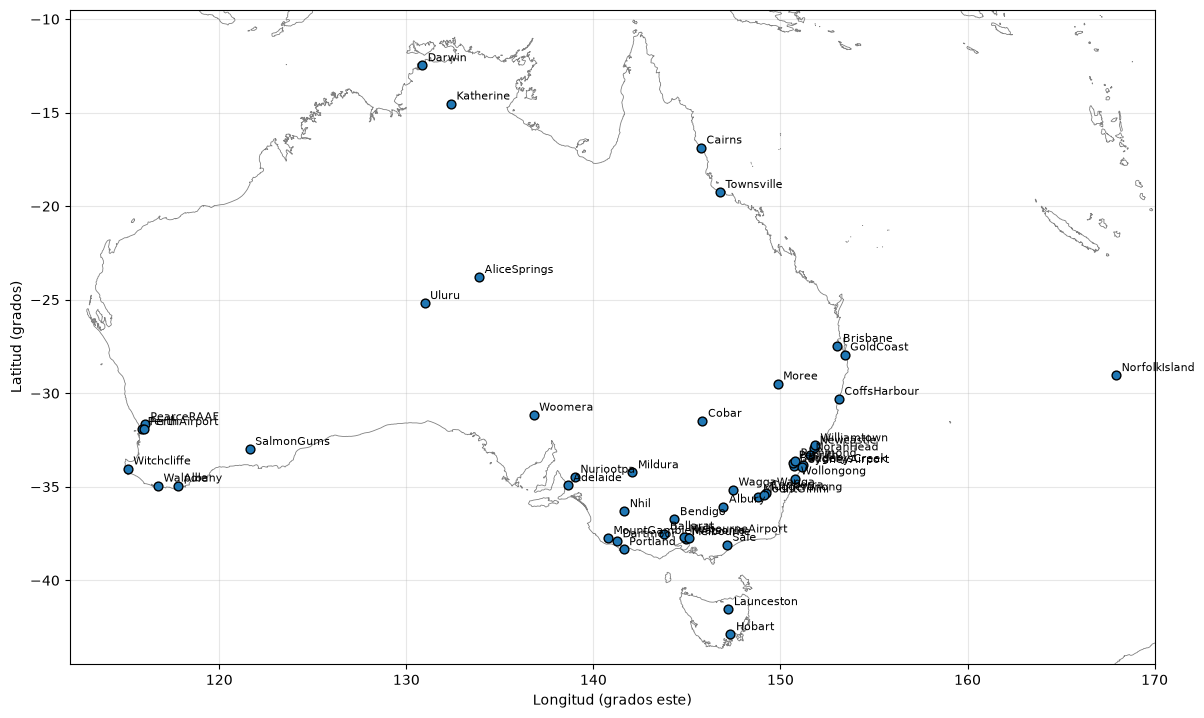

In [52]:
# Ubicación de las estaciones elegidas sobre la línea de costa, con el nombre de cada ciudad
fig, ax = plt.subplots(figsize=(14, 9))
for tramo in costa["features"]:
    vertices = np.array(tramo["geometry"]["coordinates"])
    ax.plot(vertices[:, 0], vertices[:, 1], color="gray", linewidth=0.6)
ax.scatter(tabla["longitud"], tabla["latitud"], s=40, color="tab:blue", edgecolor="black", zorder=3)
for fila in tabla.itertuples():
    ax.annotate(fila.Location, (fila.longitud, fila.latitud), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.set(xlim=(112, 170), ylim=(-44.5, -9.5), aspect="equal", xlabel="Longitud (grados este)", ylabel="Latitud (grados)")
ax.grid(alpha=0.3)
plt.show()

*Figura 1. Ubicación de la estación elegida para cada ciudad según la tabla, sobre la línea de costa de Natural Earth (en gris).*

Sobre la línea de costa (Figura 1), cada estación cae dentro de Australia y en su lugar: las ciudades
costeras sobre la costa; AliceSprings, Uluru, Woomera, Cobar y Moree en el interior; Hobart y Launceston
en Tasmania; y NorfolkIsland sobre su isla, al este del continente.

In [53]:
# Distancia entre las estaciones de cada par de ciudades
coordenadas = tabla.set_index("Location")[["latitud", "longitud"]]
lat, lon = coordenadas["latitud"].to_numpy(), coordenadas["longitud"].to_numpy()
distancia = pd.DataFrame(km(lat[:, None], lon[:, None], lat, lon), index=coordenadas.index, columns=coordenadas.index)
pares = distancia.where(np.triu(np.ones(distancia.shape, dtype=bool), k=1)).stack().dropna().sort_values()
print(f"Pares más cercanos:\n{pares.head(4).round(1).to_string()}")
print(f"Par más lejano: {pares.index[-1]}, {pares.iloc[-1]:.0f} km")

Pares más cercanos:
Location   Location     
Perth      PerthAirport      9.8
Sydney     SydneyAirport    10.0
Melbourne  Watsonia         13.4
Newcastle  Williamtown      14.4
Par más lejano: ('NorfolkIsland', 'Witchcliffe'), 4984 km


Los pares de ciudades más cercanos son Perth y PerthAirport (9,8 km) y Sydney y SydneyAirport (10,0 km).
El más lejano, NorfolkIsland y Witchcliffe, está a 4.984 km.

In [54]:
# Para cada ciudad, la otra cuya lluvia diaria más se le parece, y en qué puesto queda al ordenar las demás por cercanía
filas = []
for ciudad in coordenadas.index:
    parecida = lluvia[ciudad].drop(ciudad).idxmax()
    cercanas = distancia[ciudad].drop(ciudad).sort_values()
    filas.append({"ciudad": ciudad, "lluvia más parecida": parecida, "correlación": lluvia.loc[ciudad, parecida],
                  "km": cercanas[parecida], "puesto por cercanía": cercanas.index.get_loc(parecida) + 1, "la más cercana": cercanas.index[0]})
vecinas = pd.DataFrame(filas).set_index("ciudad").round(2)
puesto = vecinas["puesto por cercanía"]
print(f"La lluvia más parecida es la de la ciudad más cercana en {(puesto == 1).sum()} de {len(puesto)}, y una de las tres más cercanas en {(puesto <= 3).sum()}")
vecinas.sort_values("puesto por cercanía", ascending=False)

La lluvia más parecida es la de la ciudad más cercana en 36 de 49, y una de las tres más cercanas en 44


,lluvia más parecida,correlación,km,puesto por cercanía,la más cercana
ciudad,,,,,
NorfolkIsland,Uluru,0.08,3668.99,39,GoldCoast
Moree,Penrith,0.29,476.86,9,CoffsHarbour
Nhil,Bendigo,0.55,244.02,6,MountGambier
Mildura,Bendigo,0.47,344.41,4,Nhil
Woomera,Nhil,0.33,727.05,4,Nuriootpa
NorahHead,Sydney,0.66,73.04,3,Newcastle
MelbourneAirport,Watsonia,0.87,24.78,2,Melbourne
PearceRAAF,Perth,0.75,31.27,2,PerthAirport
Wollongong,SydneyAirport,0.72,77.14,2,BadgerysCreek


Si las coordenadas están bien, las ciudades cercanas deberían llover parecido. La lluvia sólo se usó para
elegir la estación de Richmond, así que para las otras 48 es un control independiente de la elección.

En 36 de las 49 ciudades, la ciudad con la lluvia más parecida es la más cercana, y en 44 es una de las
tres más cercanas. Las cinco que quedan afuera son NorfolkIsland, Moree, Nhil, Mildura y Woomera, y en
todas la ciudad de lluvia más parecida está a más de 240 km y la correlación no pasa de 0,55: no tienen
ninguna vecina que llueva igual. NorfolkIsland es el caso extremo, con una correlación de 0,08, y en la
Figura 1 está sola en el océano.